# 1. Business hypothesis and experiment overview

| Item | Value |
|---|---|
| Experiment ID | `1.1_lightgbm_ranker` (traditional models track) |
| Owner | Nigel Yap |
| Model | LightGBM gradient-boosted trees on the shared **raw** engineered feature table |
| Task | Stage one: score every candidate in each recorded impression slate (no candidates added or removed) |

**Business objective addressed.** Relevant recommendations (interim report s1.1 and s1.2.3): the initial relevance ranking that the shared reranker later adjusts for freshness, continued reading and variety.

**Hypothesis.** Two kinds of information should explain which candidate a reader clicks: (a) *freshness* (how old the article is, and how old relative to the other articles in the same slate) and (b) *personalisation* (how well the article's category, topic and article type match the user's reading history, and how deeply they read that category). Gradient-boosted trees can combine many such signals and their interactions without scaling. (This experiment does not include a linear-model comparison on this split; the validation evidence below concerns which information the model uses.)

**Two objectives are compared**, because they give different kinds of score: `binary` (click probability, the quantity the interim report defines, and what the reranker will most easily consume) and `lambdarank` (directly optimises the within-slate order). The one with the higher validation mean impression AUC is exported; ties go to `binary` because its scores are probabilities.

**Validation evidence that would support the hypothesis** (section 6): (1) ablation, retraining without the freshness group and without the personalisation group, expecting a clear AUC drop for each; (2) permutation importance of the strongest features; (3) one explained ranking for a reader.

# 2. Setup and run configuration

In [1]:
import os, sys, json, time, hashlib, platform, subprocess, pickle, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, lightgbm as lgb, pyarrow.parquet as pq
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

EXPERIMENT_ID = "1.1_lightgbm_ranker"
OWNER = "Nigel Yap"
SEED = 42
FEATURE_CASE = "raw"      # trees need no log/scaling; raw keeps the original values
TRAIN_MODEL = True        # False: load the saved model from outputs/<RUN_ID> and only export predictions
RUN_ID = os.environ.get("BT4222_RUN_ID", "20261103_seed42")
DEV_FRAC = float(os.environ.get("BT4222_DEV_FRAC", "0"))   # 0 = full data; else fraction of COMPLETE slates (dev smoke test)

# Colab: DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder")
DRIVE_ROOT = Path(os.environ.get("BT4222_DRIVE_ROOT", r"C:\Users\nigel\BT4222 Shared Final Folder"))
FEATURE_ROOT = DRIVE_ROOT / "feature_engineering"
OUT = Path("outputs") / RUN_ID
PERSIST = Path(os.environ.get("BT4222_PERSIST_DIR", str(DRIVE_ROOT / "Experiments" / EXPERIMENT_ID / RUN_ID)))
for d in ["predictions", "rankings", "model", "tuning"]: (OUT / d).mkdir(parents=True, exist_ok=True)

NON_PREDICTORS = {"split","user_id","impression_id","candidate_article_id","current_page_article_id","impression_time","clicked"}
# Fixed hyper-parameters (no search; the group asked for few, justified experiments).
COMMON = dict(learning_rate=0.08, num_leaves=63, min_data_in_leaf=100, feature_fraction=0.7,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, max_bin=127, seed=SEED,
              verbosity=-1, deterministic=True, force_row_wise=True, metric="None")
OBJECTIVES = {"binary": dict(objective="binary"),
              "lambdarank": dict(objective="lambdarank", lambdarank_truncation_level=10)}
MAX_ROUNDS, PATIENCE = 800, 40
print("run", RUN_ID, "| dev fraction", DEV_FRAC, "| lightgbm", lgb.__version__, "| pandas", pd.__version__)

run 20261103_seed42 | dev fraction 0.0 | lightgbm 4.7.0 | pandas 2.2.3


**Selection protocol.** Primary metric is **mean impression AUC** (maximised for early stopping and for choosing between the two objectives); secondary is **mean impression nDCG@5**. Early stopping uses the validation split, so every validation number below is a **development/validation result**, not an untouched final test. The test split has no click labels: it is only scored, never evaluated.

In [2]:
def auc_by_slate(g, y, s):
    d = pd.DataFrame({"g": g, "y": y, "s": s})
    d["r"] = d.groupby("g", sort=False)["s"].rank(method="average")
    a = d.assign(ry=d.r * d.y).groupby("g", sort=False).agg(n=("y","size"), pos=("y","sum"), ry=("ry","sum"))
    neg = a.n - a.pos
    ok = (a.pos > 0) & (neg > 0)
    return ((a.ry - a.pos*(a.pos+1)/2) / (a.pos*neg))[ok].mean(), int(ok.sum()), int(len(a) - ok.sum())

def evaluate_slates(g, y, s, k=5):
    """Equal-weight mean over impressions; ties get expected credit; counts and exclusions reported."""
    g, y, s = np.asarray(g), np.asarray(y, dtype="float64"), np.asarray(s, dtype="float64")
    auc, n_auc, ex_auc = auc_by_slate(g, y, s)
    d = pd.DataFrame({"g": g, "y": y, "s": s})
    d["ty"] = d.groupby(["g", "s"], sort=False)["y"].transform("mean")
    d = d.sort_values(["g", "s"], ascending=[True, False], kind="stable")
    d["pos"] = d.groupby("g", sort=False).cumcount() + 1
    dcg = (d.ty / np.log2(d.pos + 1)).where(d.pos <= k, 0).groupby(d.g, sort=False).sum()
    npos = d.groupby("g", sort=False)["y"].sum()
    disc = np.r_[0, np.cumsum(1 / np.log2(np.arange(1, k + 1) + 1))]
    ideal = pd.Series(disc[np.minimum(npos.to_numpy(), k).astype(int)], index=npos.index)
    ok = npos > 0
    ndcg = (dcg[ok] / ideal[ok]).mean()
    return {"mean_impression_auc": float(auc), f"mean_impression_ndcg@{k}": float(ndcg),
            "candidate_rows": int(len(d)), "impressions": int(d.g.nunique()),
            "auc_eligible_impressions": n_auc, "auc_excluded_one_label_class": ex_auc,
            "ndcg_eligible_impressions": int(ok.sum()), "ndcg_excluded_no_positive": int((~ok).sum())}

# 3. Load and check shared data

In [3]:
def load_split(split):
    path = FEATURE_ROOT / f"{split}_features.parquet"
    names = pq.ParquetFile(path).schema_arrow.names
    feats = [c for c in names if c not in NON_PREDICTORS and not c.endswith("_log1p")]   # 'raw' case
    cols = ["user_id","impression_id","candidate_article_id"] + feats + (["clicked"] if split != "test" else [])
    df = pd.read_parquet(path, columns=cols)
    dups = int(df.duplicated(["user_id","impression_id","candidate_article_id"]).sum())
    assert dups == 0, f"{split}: {dups} duplicate candidate keys - investigate, do not deduplicate silently"
    df["behaviour_id"] = df.user_id.astype("int64").astype(str) + ":" + df.impression_id.astype("int64").astype(str)
    if DEV_FRAC > 0:      # keep COMPLETE slates only
        ids = df.behaviour_id.unique()
        keep = set(np.random.default_rng(SEED).choice(ids, int(len(ids) * DEV_FRAC), replace=False))
        df = df[df.behaviour_id.isin(keep)]
    df["g"] = pd.factorize(df.behaviour_id)[0]
    df = df.sort_values("g", kind="stable").reset_index(drop=True)      # contiguous slates for ranking objectives
    return df, feats

data, FEATURES = {}, None
for sp in ["train", "validation", "test"]:
    data[sp], f = load_split(sp)
    FEATURES = FEATURES or f
    assert f == FEATURES, "feature order differs between splits"
    d = data[sp]
    lab = d.clicked.notna().mean() if "clicked" in d else 0
    print(f"{sp:10s} rows={len(d):>9,} impressions={d.g.nunique():>8,} labelled={lab:.0%}"
          + (f" click_rate={d.clicked.mean():.4f}" if sp != "test" else ""))
print(len(FEATURES), "predictors; example order:", FEATURES[:6], "...")
nulls = data["train"][FEATURES].isna().mean().sort_values(ascending=False)
print("most-missing predictors (train):", nulls[nulls > 0].head(5).round(3).to_dict())

train      rows=2,585,747 impressions= 232,887 labelled=100% click_rate=0.0904


validation rows=  344,666 impressions=  29,110 labelled=100% click_rate=0.0849


test       rows=  446,915 impressions=  29,085 labelled=0%
202 predictors; example order: ['is_sso_user', 'is_subscriber', 'is_front_page', 'hour', 'day_of_week', 'slate_size'] ...


most-missing predictors (train): {'slate_relative_age_h': 0.239, 'same_category_mean_read_time': 0.053, 'body_word_count': 0.017, 'candidate_topic_preference': 0.001, 'has_any_topic_overlap': 0.001}


# 4. Prepare model inputs

In [4]:
# Trees handle missing values natively, so nothing is imputed or scaled: missingness stays distinct from zero
# (the shared files already carry *_missing indicator columns). No transform is fitted, so nothing can leak.
PREPROCESSING = {"feature_case": FEATURE_CASE, "features": FEATURES, "imputation": "none (LightGBM native NaN handling)",
                 "scaling": "none", "ids_and_target_excluded": sorted(NON_PREDICTORS)}
def X_of(sp, cols=None): return data[sp][cols or FEATURES].to_numpy(dtype="float32")
def sizes_of(sp): return np.bincount(data[sp].g.to_numpy())

GROUPS = {   # feature groups for the ablation (section 6)
    "freshness": ["article_age_h", "article_age_missing", "is_24h_eligible", "slate_relative_age_h"],
    "personalisation": [c for c in FEATURES if c.startswith(("hist_", "candidate_category_pref", "candidate_article_type_pref",
        "candidate_topic_pref", "category_affinity", "last5_mean_topic", "topic_affinity", "has_any_topic_overlap",
        "same_category_"))],
}
for k, v in GROUPS.items(): print(f"{k}: {len(v)} columns")
assert set(sum(GROUPS.values(), [])) <= set(FEATURES)

freshness: 4 columns
personalisation: 129 columns


# 5. Define and train / load model

In [5]:
val = data["validation"]
yv, gv = val.clicked.to_numpy(), val.g.to_numpy()
_cache = {}
def feval(preds, ds):          # primary selection metric, evaluated on the validation split at every round
    return "impression_auc", auc_by_slate(gv, yv, preds)[0], True

def train_model(objective, cols, tag):
    Xt, yt = X_of("train", cols), data["train"].clicked.to_numpy()
    Xv = X_of("validation", cols)
    grp = lambda sp: dict(group=sizes_of(sp)) if objective == "lambdarank" else {}
    dtr = lgb.Dataset(Xt, yt, feature_name=cols, free_raw_data=False, **grp("train"))
    dva = lgb.Dataset(Xv, yv, reference=dtr, feature_name=cols, free_raw_data=False, **grp("validation"))
    t0 = time.time(); hist = {}
    bst = lgb.train({**COMMON, **OBJECTIVES[objective]}, dtr, MAX_ROUNDS, valid_sets=[dva], valid_names=["validation"],
                    feval=feval, callbacks=[lgb.early_stopping(PATIENCE, verbose=False), lgb.record_evaluation(hist)])
    pv = bst.predict(Xv, num_iteration=bst.best_iteration)
    m = evaluate_slates(gv, yv, pv)
    m.update(objective=objective, tag=tag, n_features=len(cols), best_iteration=int(bst.best_iteration),
             seconds=round(time.time() - t0))
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()
           if k in ("tag","objective","n_features","best_iteration","mean_impression_auc","mean_impression_ndcg@5","seconds")})
    return bst, pv, m, hist["validation"]["impression_auc"]

if TRAIN_MODEL:
    runs = {o: train_model(o, FEATURES, f"full_{o}") for o in OBJECTIVES}
    comp = pd.DataFrame([r[2] for r in runs.values()])
    # primary: validation mean impression AUC; secondary nDCG@5; tie-breaker: binary (probability scores)
    comp["_rank"] = comp.objective.map({"binary": 0, "lambdarank": 1})
    CHOSEN = comp.sort_values(["mean_impression_auc", "mean_impression_ndcg@5", "_rank"], ascending=[False, False, True]).objective.iloc[0]
    booster, val_scores, val_metrics, curve = runs[CHOSEN]
    comp.drop(columns="_rank").to_csv(OUT / "tuning" / "trials.csv", index=False)
    booster.save_model(str(OUT / "model" / "lightgbm_model.txt"), num_iteration=booster.best_iteration)
    BEST_ITER = int(booster.best_iteration)
else:
    cfg = json.loads((OUT / "run_config.json").read_text())
    CHOSEN, BEST_ITER = cfg["objective"], cfg["selected_iteration"]
    booster = lgb.Booster(model_file=str(OUT / "model" / "lightgbm_model.txt"))
    val_scores = booster.predict(X_of("validation")); val_metrics = evaluate_slates(gv, yv, val_scores)
    comp = pd.read_csv(OUT / "tuning" / "trials.csv"); curve = None
print("\nCHOSEN objective:", CHOSEN, "| trees:", BEST_ITER)
comp[["objective","best_iteration","mean_impression_auc","mean_impression_ndcg@5","seconds"]].round(4)

{'mean_impression_auc': 0.7561, 'mean_impression_ndcg@5': 0.5935, 'objective': 'binary', 'tag': 'full_binary', 'n_features': 202, 'best_iteration': 165, 'seconds': 67}


{'mean_impression_auc': 0.7533, 'mean_impression_ndcg@5': 0.5904, 'objective': 'lambdarank', 'tag': 'full_lambdarank', 'n_features': 202, 'best_iteration': 182, 'seconds': 75}

CHOSEN objective: binary | trees: 165


,objective,best_iteration,mean_impression_auc,mean_impression_ndcg@5,seconds
0,binary,165,0.7561,0.5935,67
1,lambdarank,182,0.7533,0.5904,75


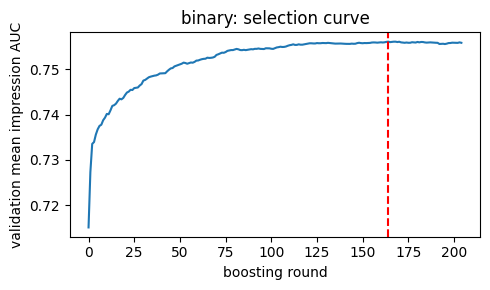

In [6]:
if curve is not None:
    plt.figure(figsize=(5, 3)); plt.plot(curve); plt.axvline(BEST_ITER - 1, color="r", ls="--")
    plt.xlabel("boosting round"); plt.ylabel("validation mean impression AUC"); plt.title(f"{CHOSEN}: selection curve"); plt.tight_layout(); plt.show()

# 6. Validation diagnostics and explainability

In [7]:
# (a) Targeted ablation: retrain the chosen objective without one feature group, compare validation AUC / nDCG@5.
ABL = OUT / "tuning" / "ablation.csv"
if TRAIN_MODEL:
    rows = [dict(removed="none (full model)", n_features=len(FEATURES), **{k: val_metrics[k] for k in ("mean_impression_auc","mean_impression_ndcg@5")})]
    for name, cols in GROUPS.items():
        keep = [c for c in FEATURES if c not in set(cols)]
        _, _, m, _ = train_model(CHOSEN, keep, f"without_{name}")
        rows.append(dict(removed=name, n_features=len(keep), **{k: m[k] for k in ("mean_impression_auc","mean_impression_ndcg@5")}))
    abl = pd.DataFrame(rows); abl.to_csv(ABL, index=False)
abl = pd.read_csv(ABL)
abl["d_auc"] = abl.mean_impression_auc - abl.mean_impression_auc.iloc[0]
abl["d_ndcg@5"] = abl["mean_impression_ndcg@5"] - abl["mean_impression_ndcg@5"].iloc[0]
abl.round(4)

{'mean_impression_auc': 0.6594, 'mean_impression_ndcg@5': 0.4833, 'objective': 'binary', 'tag': 'without_freshness', 'n_features': 198, 'best_iteration': 85, 'seconds': 42}


{'mean_impression_auc': 0.7256, 'mean_impression_ndcg@5': 0.5556, 'objective': 'binary', 'tag': 'without_personalisation', 'n_features': 73, 'best_iteration': 95, 'seconds': 30}


,removed,n_features,mean_impression_auc,mean_impression_ndcg@5,d_auc,d_ndcg@5
0,none (full model),202,0.7561,0.5935,0.0000,0.0000
1,freshness,198,0.6594,0.4833,-0.0966,-0.1103
2,personalisation,73,0.7256,0.5556,-0.0305,-0.0379


share of total gain: freshness 42.5%  personalisation 13.9%  other 43.5%


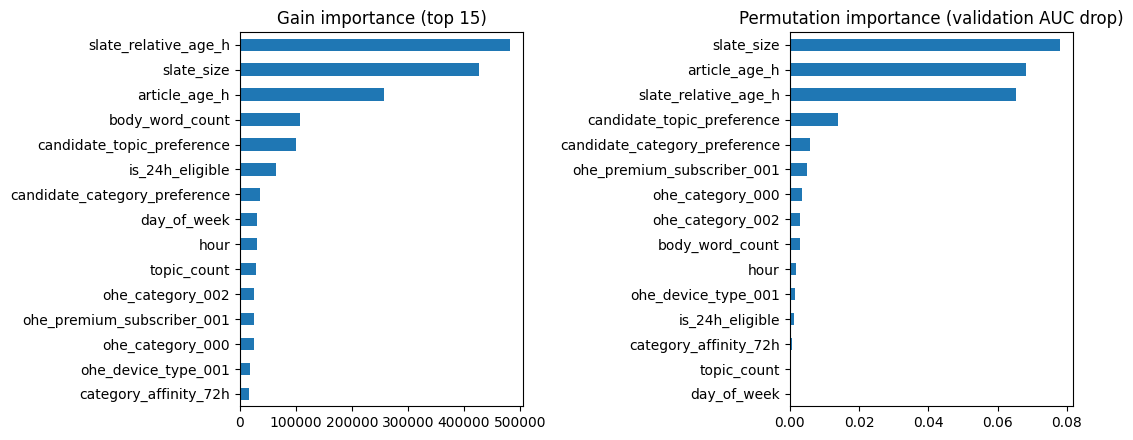

In [8]:
# (b) Gain importance by feature and by group, and permutation importance of the top features on a validation subset.
gain = pd.Series(booster.feature_importance("gain"), index=FEATURES).sort_values(ascending=False)
gain.to_csv(OUT / "tuning" / "gain_importance.csv", header=["gain"])
share = gain / gain.sum()
print("share of total gain: freshness %.1f%%  personalisation %.1f%%  other %.1f%%" % (
    100 * share[GROUPS["freshness"]].sum(), 100 * share[GROUPS["personalisation"]].sum(),
    100 * share.drop(sum(GROUPS.values(), []), errors="ignore").sum()))

rng = np.random.default_rng(SEED)
sub_g = rng.choice(val.g.unique(), min(5000, val.g.nunique()), replace=False)
sub = val[val.g.isin(sub_g)]
Xs, ys, gs = sub[FEATURES].to_numpy("float32"), sub.clicked.to_numpy(), sub.g.to_numpy()
base = auc_by_slate(gs, ys, booster.predict(Xs, num_iteration=BEST_ITER))[0]
perm = {}
for f in gain.index[:15]:
    j = FEATURES.index(f); drops = []
    for rep in range(3):
        Xp = Xs.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base - auc_by_slate(gs, ys, booster.predict(Xp, num_iteration=BEST_ITER))[0])
    perm[f] = np.mean(drops)
perm = pd.Series(perm).sort_values()
perm.to_csv(OUT / "tuning" / "permutation_importance.csv", header=["auc_drop"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
gain.head(15).iloc[::-1].plot.barh(ax=ax[0], title="Gain importance (top 15)")
perm.plot.barh(ax=ax[1], title="Permutation importance (validation AUC drop)"); plt.tight_layout(); plt.show()

In [9]:
# (c) One explained ranking for a reader (per-feature contributions to the score, LightGBM pred_contrib).
ok = sub.groupby("g").agg(n=("clicked","size"), c=("clicked","sum"))
gid = ok[(ok.n.between(8, 12)) & (ok.c == 1)].index[0]
one = sub[sub.g == gid].copy()
one["score"] = booster.predict(one[FEATURES].to_numpy("float32"), num_iteration=BEST_ITER, raw_score=True)
one = one.sort_values("score", ascending=False)
contrib = booster.predict(one[FEATURES].to_numpy("float32"), num_iteration=BEST_ITER, pred_contrib=True)[:, :-1]
print("Behaviour", one.behaviour_id.iloc[0], "- candidates ranked by model (clicked = actual click):")
print(one[["candidate_article_id", "clicked", "score", "article_age_h", "category_affinity_72h"]].round(3).to_string(index=False))
for label, idx in [("top-ranked candidate", 0), ("clicked candidate", int(np.argmax(one.clicked.to_numpy())))]:
    c = pd.Series(contrib[idx], index=FEATURES); top = c.reindex(c.abs().sort_values(ascending=False).index).head(5)
    print(f"\nWhy {label} (article {one.candidate_article_id.iloc[idx]}), top 5 contributions to the raw score:")
    print(pd.DataFrame({"contribution": top.round(3), "value": one[FEATURES].iloc[idx][top.index].round(3)}).to_string())

Behaviour 1083980:668712 - candidates ranked by model (clicked = actual click):
 candidate_article_id  clicked  score  article_age_h  category_affinity_72h
              9785424        1 -0.877          1.854                  0.171
              9785437        0 -1.082          1.413                  0.269
              9785553        0 -1.335          0.541                  0.235
              9785593        0 -1.618          0.132                  0.235
              9785471        0 -1.649          1.257                  0.172
              9785475        0 -1.813          1.286                  0.171
              9785298        0 -1.823          0.328                  0.235
              9785020        0 -2.129          0.730                  0.054
              9780604        0 -2.875          0.649                  0.172

Why top-ranked candidate (article 9785424), top 5 contributions to the raw score:
                      contribution     value
slate_relative_age_h         0.8

In [10]:
# (d) Handoff diagnostics for the reranker: does the top of each slate concentrate on one category / on very fresh articles?
cat_cols = [c for c in FEATURES if c.startswith("ohe_category_")]
v = val.assign(score=val_scores)
v["cat"] = np.argmax(v[cat_cols].fillna(0).to_numpy(), axis=1)
v = v.sort_values(["g", "score"], ascending=[True, False], kind="stable"); v["rank"] = v.groupby("g").cumcount() + 1
top5 = v[v["rank"] <= 5]
print("median article age (h): all candidates %.2f | model top-5 %.2f" % (v.article_age_h.median(), top5.article_age_h.median()))
print("distinct categories in a top-5: mean %.2f | share of top-5 in the slate's modal category: %.2f" % (
    top5.groupby("g").cat.nunique().mean(), top5.groupby("g").cat.agg(lambda s: s.value_counts().iloc[0] / len(s)).mean()))

median article age (h): all candidates 4.94 | model top-5 3.40


distinct categories in a top-5: mean 3.39 | share of top-5 in the slate's modal category: 0.47


**Reading the evidence (validation / development results, full run).**

- **Objective choice.** `binary` (AUC 0.7561, nDCG@5 0.5935) edges out `lambdarank` (0.7533, 0.5904), so the simpler objective, whose scores are click probabilities, is exported. The gap is small, so we should not claim one objective is fundamentally better; the practical reason to prefer `binary` is that the reranker can use its scores as probabilities.
- **Freshness is the strongest signal.** Removing the 4 freshness columns lowers AUC by **0.097** (0.756 to 0.659) and nDCG@5 by 0.110; freshness columns carry 42.5% of the total gain, with `slate_relative_age_h` and `article_age_h` among the top three features. Readers mostly click the newest articles shown, and how new an article is *relative to the rest of the slate* matters as much as its absolute age.
- **Personalisation adds a smaller but real gain.** Removing the 129 history-preference columns lowers AUC by **0.031** and nDCG@5 by 0.038. `candidate_topic_preference` and `candidate_category_preference` are the most useful of these. The hypothesis is therefore supported in order of strength: freshness first, history-based personalisation second.
- **Permutation importance agrees on the ranking of the top features** (article age, slate-relative age, topic preference), with one caveat. `slate_size` also scores high (AUC drop about 0.078), but it takes the same value for every candidate in a slate, so it can only change the *order within a slate* through interactions with candidate features, and shuffling it row by row breaks that constancy. Treat its importance as an interaction/proxy effect (for example, slate composition) and not as evidence that slate size itself drives clicks.
- **Explained reader (section c).** In the example slate the clicked article was also the top-ranked one; its score was driven mainly by being newer than the slate median (`slate_relative_age_h`), the slate size, and its age. This is one anecdote, not a general statement.
- **Limits.** Importances and contributions describe what the model *uses*, not what *causes* clicks; correlated features share credit, which is why the group ablation is the stronger evidence. The ablation retrains each time with early stopping on the same validation split, so all of these are development results.

# 7. Predict and export all splits

In [11]:
def score_split(sp):
    d = data[sp]; s = booster.predict(X_of(sp), num_iteration=BEST_ITER)
    return d, s

def export_split(sp, d, s):
    sc = pd.DataFrame({"behaviour_id": d.behaviour_id.to_numpy(), "article_id": d.candidate_article_id.astype("int64").to_numpy(),
                       "score": s, "g": d.g.to_numpy()})
    assert np.isfinite(sc.score).all(), "non-finite scores"
    if CHOSEN == "binary": sc["click_probability"] = sc.score; assert sc.click_probability.between(0, 1).all()
    keycols = ["behaviour_id", "article_id", "score"] + (["click_probability"] if CHOSEN == "binary" else [])
    sc.sort_values(["behaviour_id", "article_id"], kind="stable")[keycols].to_csv(OUT / "predictions" / f"{sp}_scores.csv", index=False)
    rk = sc.sort_values(["g", "score", "article_id"], ascending=[True, False, True], kind="stable")
    lists = rk.groupby("g", sort=False).agg(behaviour_id=("behaviour_id", "first"),
                                          article_ids=("article_id", lambda a: json.dumps([int(x) for x in a])))
    sizes = rk.groupby("g", sort=False).size()
    assert (lists.article_ids.map(lambda t: len(json.loads(t))).to_numpy() == sizes.to_numpy()).all(), "ranking lost/added candidates"
    lists.sort_values("behaviour_id")[["behaviour_id", "article_ids"]].to_csv(OUT / "rankings" / f"{sp}_ranked_articles.csv", index=False)
    return dict(rows=int(len(sc)), behaviours=int(sc.g.nunique()), rankings=int(len(lists)))

scores, export_counts, split_metrics = {}, {}, {}
for sp in ["train", "validation", "test"]:
    d, s = score_split(sp); scores[sp] = s
    export_counts[sp] = export_split(sp, d, s)
    if sp != "test":
        split_metrics[sp] = evaluate_slates(d.g.to_numpy(), d.clicked.to_numpy(), s)
    print(sp, export_counts[sp])
assert np.allclose(scores["validation"], val_scores)
print("train metrics are IN-SAMPLE diagnostics; test has no labels, so no test metric is reported.")
pd.DataFrame(split_metrics).T.round(4)

train {'rows': 2585747, 'behaviours': 232887, 'rankings': 232887}


validation {'rows': 344666, 'behaviours': 29110, 'rankings': 29110}


test {'rows': 446915, 'behaviours': 29085, 'rankings': 29085}
train metrics are IN-SAMPLE diagnostics; test has no labels, so no test metric is reported.


,mean_impression_auc,mean_impression_ndcg@5,candidate_rows,impressions,auc_eligible_impressions,auc_excluded_one_label_class,ndcg_eligible_impressions,ndcg_excluded_no_positive
train,0.8047,0.6671,2585747.0,232887.0,232887.0,0.0,232887.0,0.0
validation,0.7561,0.5935,344666.0,29110.0,29110.0,0.0,29110.0,0.0


In [12]:
def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def git(*a):
    try: return subprocess.run(["git", *a], capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception: return "unavailable"
files = {sp: dict(path=str(FEATURE_ROOT / f"{sp}_features.parquet"), sha256=sha256(FEATURE_ROOT / f"{sp}_features.parquet"),
                  rows=export_counts[sp]["rows"]) for sp in ["train", "validation", "test"]}
cfg = dict(experiment_id=EXPERIMENT_ID, run_id=RUN_ID, owner=OWNER, seed=SEED, export_schema_version=2,
    dev_sample_fraction=DEV_FRAC or None, feature_case=FEATURE_CASE, objective=CHOSEN, selected_iteration=BEST_ITER,
    selection=dict(objective="maximise mean impression AUC on the validation split", secondary="mean impression nDCG@5",
                   tie_breaker="binary over lambdarank", early_stopping_patience=PATIENCE, partition="validation (development/validation results)"),
    hyperparameters={**COMMON, **OBJECTIVES[CHOSEN]}, max_rounds=MAX_ROUNDS,
    score_semantics=dict(score_type="probability" if CHOSEN == "binary" else "ranking_score",
                         source="LightGBM Booster.predict (sigmoid output)" if CHOSEN == "binary" else "LightGBM raw lambdarank score",
                         conversion="none", click_probability_column=(CHOSEN == "binary")),
    features=FEATURES, n_features=len(FEATURES), preprocessing=PREPROCESSING["imputation"],
    inputs=files, exports=export_counts, complete_slate_coverage=True, test_labels="unavailable (not evaluated)",
    packages=dict(python=platform.python_version(), lightgbm=lgb.__version__, pandas=pd.__version__, numpy=np.__version__),
    code_commit=git("rev-parse", "HEAD"), uncommitted_changes=bool(git("status", "--porcelain")),
    persistent_artifact_location=str(PERSIST))
(OUT / "run_config.json").write_text(json.dumps(cfg, indent=2))
(OUT / "metrics.json").write_text(json.dumps(dict(
    note="validation = development/validation results (used for early stopping and objective choice); train = in-sample; test has no labels",
    primary="mean_impression_auc", secondary="mean_impression_ndcg@5", validation=split_metrics["validation"],
    train_in_sample=split_metrics["train"], objective_comparison=json.loads(comp.drop(columns="_rank", errors="ignore").to_json(orient="records")),
    ablation=json.loads(abl.to_json(orient="records"))), indent=2))
pickle.dump(PREPROCESSING, open(OUT / "model" / "preprocessing.pkl", "wb"))
(OUT / "model" / "model_config.json").write_text(json.dumps(dict(library="lightgbm", model_file="lightgbm_model.txt", objective=CHOSEN,
    num_iteration=BEST_ITER, feature_names=FEATURES, load="lgb.Booster(model_file=...); booster.predict(X[features], num_iteration=num_iteration)"), indent=2))
(OUT / "requirements.txt").write_text(f"lightgbm=={lgb.__version__}\npandas=={pd.__version__}\nnumpy=={np.__version__}\npyarrow\nmatplotlib\n")
print("saved run bundle to", OUT.resolve())

saved run bundle to C:\Users\nigel\bt4222-repo\Experiments\1.1_lightgbm_ranker\outputs\20261103_seed42


# 8. Reload check

In [13]:
# Copy the complete run to the persistent location, then reload from THAT copy (no retraining) and compare.
if PERSIST.resolve() != OUT.resolve():
    shutil.copytree(OUT, PERSIST, dirs_exist_ok=True)
reloaded = lgb.Booster(model_file=str(PERSIST / "model" / "lightgbm_model.txt"))
pre = pickle.load(open(PERSIST / "model" / "preprocessing.pkl", "rb"))
saved = pd.read_csv(PERSIST / "predictions" / "validation_scores.csv").head(20000)
chk = saved.merge(val[["behaviour_id","candidate_article_id"] + pre["features"]].rename(columns={"candidate_article_id": "article_id"}),
                  on=["behaviour_id", "article_id"])
new = reloaded.predict(chk[pre["features"]].to_numpy("float32"), num_iteration=json.loads((PERSIST / "model" / "model_config.json").read_text())["num_iteration"])
TOL = 1e-8
err = float(np.abs(new - chk.score.to_numpy()).max())
print(f"reloaded from {PERSIST}\n{len(chk):,} rows compared | max abs difference vs exported CSV = {err:.2e} | tolerance {TOL:.0e}")
assert err < TOL, "reload check FAILED"
print("RELOAD CHECK PASSED")

reloaded from C:\Users\nigel\BT4222 Shared Final Folder\Experiments\1.1_lightgbm_ranker\20261103_seed42
20,000 rows compared | max abs difference vs exported CSV = 9.97e-17 | tolerance 1e-08
RELOAD CHECK PASSED


# 9. Business interpretation and handoff

In [14]:
print(f"Chosen objective: {CHOSEN} ({BEST_ITER} trees); validation (development) mean impression AUC = {val_metrics['mean_impression_auc']:.4f}, nDCG@5 = {val_metrics['mean_impression_ndcg@5']:.4f}")
print("Bundle (local):", OUT.resolve()); print("Bundle (persistent copy):", PERSIST.resolve())

Chosen objective: binary (165 trees); validation (development) mean impression AUC = 0.7561, nDCG@5 = 0.5935
Bundle (local): C:\Users\nigel\bt4222-repo\Experiments\1.1_lightgbm_ranker\outputs\20261103_seed42
Bundle (persistent copy): C:\Users\nigel\BT4222 Shared Final Folder\Experiments\1.1_lightgbm_ranker\20261103_seed42


**Finding.** On the shared 80/10/10 split, a LightGBM click model on the raw engineered features reaches validation (development) mean impression AUC **0.7561** and nDCG@5 **0.5935**. Train in-sample values are 0.8047 and 0.6671; this gap indicates moderate overfitting, which early stopping limited. The test split has no labels, so nothing is claimed about test.

**Relation to the business objective.** The model supports the *relevant recommendations* objective: it ranks clicked candidates higher than unclicked ones within a slate. It does not by itself show retention or continued reading; those need session labels and the shared evaluation stage.

**For the reranker (freshness and variety).**
- The model already favours fresh articles: the median age is 4.9 h across all candidates and 3.4 h among the model's top-5. A freshness reranking step will therefore add little, and pushing recency further risks lowering relevance.
- Variety: a top-5 list contains on average 3.4 distinct categories, and 47% of the top-5 sits in the slate's most common category. This is a baseline for measuring whether the diversity reranker changes these numbers.

**Limitations.** Selection used the validation split (so results are development results); hyper-parameters were fixed, not searched; the ablation groups are broad (freshness 4 columns, personalisation 129); `slate_size` importance is an interaction effect; and click labels reflect exposure, not dislike.

**Handoff.** Bundle: `Experiments/1.1_lightgbm_ranker/outputs/20261103_seed42/` (persistent copy under the shared folder). It holds `predictions/{train,validation,test}_scores.csv` (`behaviour_id, article_id, score, click_probability`; `score_type = probability`), `rankings/{train,validation,test}_ranked_articles.csv` (complete slates, JSON arrays), `model/` (LightGBM text model, `preprocessing.pkl`, `model_config.json`), `metrics.json`, `run_config.json` (`export_schema_version = 2`) and `tuning/` (objective comparison, ablation and importance tables). The reload check from the persistent copy matched the exported scores to 1e-16 (tolerance 1e-8).

**Text-similarity features (earlier exploratory finding).** Before the dataset switch, on the larger EB-NeRD sample (every-10th-user sample, a different split), adding TF-IDF cosine and BM25 similarity between a candidate and the user's recent clicks changed validation AUC by only about +0.0002 (0.7448 to 0.7450) over the engineered features, which is no practical gain. No significance test was run and the features were not re-tested on the shared split, so they are not included in this experiment.